<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Cuadernos/00_Intro_PLN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Introducción al Procesamiento del Lenguaje Natural</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Introducción</span>](#introduccion)
- [<span style="color: #005C99;">¿Qué es el PLN?</span>](#que-es-el-pln)
- [<span style="color: #005C99;">Niveles de análisis y ambigüedad</span>](#niveles-de-analisis-y-ambiguedad)
- [<span style="color: #005C99;">Historia del PLN</span>](#historia-del-pln)
- [<span style="color: #005C99;">Un chatbot de 1966: ELIZA</span>](#un-chatbot-de-1966-eliza)
- [<span style="color: #005C99;">Tareas y aplicaciones</span>](#tareas-y-aplicaciones)
- [<span style="color: #005C99;">El texto como dato: la ley de Zipf</span>](#el-texto-como-dato-la-ley-de-zipf)
- [<span style="color: #005C99;">Tendencias actuales</span>](#tendencias-actuales)
- [<span style="color: #005C99;">Herramientas en Python</span>](#herramientas-en-python)
- [<span style="color: #005C99;">Ruta del curso</span>](#ruta-del-curso)
- [<span style="color: #005C99;">Referencias</span>](#referencias)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib nltk

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Recursos de NLTK usados en este cuaderno
for recurso in ["gutenberg", "punkt", "punkt_tab"]:
    nltk.download(recurso, quiet=True)

<a id="introduccion"></a>
<h2 style="color: #007ACC;">Introducción</h2>

El **Procesamiento del Lenguaje Natural** (PLN, o *NLP* por sus siglas en inglés) es el área de la inteligencia artificial que estudia cómo lograr que los computadores **analicen, comprendan y generen lenguaje humano**, ya sea escrito o hablado.

El lenguaje es probablemente el dato más abundante que producimos: correos, chats, documentos legales, historias clínicas, reseñas, publicaciones en redes sociales, transcripciones de llamadas... Casi todo el conocimiento humano está codificado en texto. Por eso el PLN está detrás de herramientas que usamos a diario: buscadores, traductores, correctores ortográficos, asistentes de voz, filtros de spam y, más recientemente, los grandes modelos de lenguaje (*LLM*) como ChatGPT o Claude.

En este cuaderno veremos qué es el PLN, por qué es difícil, cómo ha evolucionado, qué tareas resuelve y con qué herramientas trabajaremos durante el curso.

<a id="que-es-el-pln"></a>
<h2 style="color: #007ACC;">¿Qué es el PLN?</h2>

El PLN se ubica en la intersección de tres disciplinas:

- **Lingüística:** aporta la teoría sobre cómo se estructura el lenguaje (sonidos, palabras, oraciones, significado).
- **Ciencias de la computación:** aporta algoritmos y estructuras de datos para procesar texto eficientemente.
- **Aprendizaje automático / estadística:** aporta modelos que **aprenden patrones a partir de datos** en lugar de reglas escritas a mano.

Suele dividirse en dos grandes familias de problemas:

| Familia | Pregunta que responde | Ejemplos |
|---------|----------------------|----------|
| **Comprensión** (*NLU*) | ¿Qué significa este texto? | Clasificación de sentimiento, extracción de entidades, respuesta a preguntas |
| **Generación** (*NLG*) | ¿Cómo produzco texto adecuado? | Traducción, resumen automático, chatbots |

Formalmente, casi cualquier tarea de PLN puede verse como aprender una función $f: \mathcal{X} \rightarrow \mathcal{Y}$ donde $\mathcal{X}$ es un espacio de textos. Lo que cambia es $\mathcal{Y}$: una etiqueta (clasificación), una secuencia de etiquetas (etiquetado gramatical) u otro texto (traducción).

<a id="niveles-de-analisis-y-ambiguedad"></a>
<h2 style="color: #007ACC;">Niveles de análisis y ambigüedad</h2>

El lenguaje puede analizarse en varios niveles. Cada uno trae sus propios retos computacionales:

| Nivel | Estudia | Ejemplo de tarea |
|-------|---------|------------------|
| Fonética / fonología | Sonidos del habla | Reconocimiento de voz |
| Morfología | Estructura interna de las palabras (*cant-ábamos*) | Lematización, *stemming* |
| Sintaxis | Cómo se combinan las palabras en oraciones | Etiquetado gramatical, análisis sintáctico |
| Semántica | Significado de palabras y oraciones | Desambiguación, similitud semántica |
| Pragmática / discurso | Significado en contexto e intención | Detección de ironía, diálogo |

<h3 style="color: #007ACC;">¿Por qué es difícil el PLN?</h3>

El principal enemigo es la **ambigüedad**, que aparece en todos los niveles:

- **Léxica:** *"Fui al **banco**"* (¿entidad financiera o asiento?).
- **Sintáctica:** *"Vi al hombre **con el telescopio**"* (¿quién tiene el telescopio?).
- **Referencial:** *"Juan le dijo a Pedro que **él** ganaría"* (¿quién es *él*?).
- **Pragmática:** *"¡Qué buen servicio! Solo esperé tres horas"* (ironía: el sentimiento real es negativo).

A esto se suman la **variabilidad** (hay infinitas formas de decir lo mismo), la **dependencia del contexto**, el lenguaje informal (*"q mas parce, nos vms ahorita"*), los errores ortográficos, la mezcla de idiomas y la evolución constante del vocabulario.

<a id="historia-del-pln"></a>
<h2 style="color: #007ACC;">Historia del PLN</h2>

La historia del PLN puede resumirse en cuatro grandes paradigmas:

| Periodo | Paradigma | Hitos |
|---------|-----------|-------|
| 1950–1980 | **Simbólico / basado en reglas** | Test de Turing (1950); experimento Georgetown–IBM de traducción automática (1954); ELIZA (1966); informe ALPAC (1966) que frenó la financiación de la traducción automática; SHRDLU (1970) |
| 1980–2010 | **Estadístico** | Modelos ocultos de Markov para reconocimiento de voz y etiquetado; modelos de N-gramas; traducción automática estadística de IBM (1990s); Naive Bayes, máxima entropía y CRF |
| 2010–2017 | **Redes neuronales** | Modelo de lenguaje neuronal de Bengio (2003); Word2Vec (2013); GloVe (2014); Seq2Seq con LSTM (2014); mecanismo de atención (2015) |
| 2017–hoy | **Transformers y preentrenamiento** | *Attention Is All You Need* (2017); BERT y GPT (2018); GPT-3 y el aprendizaje en contexto (2020); ChatGPT (2022); LLM abiertos y multimodales (2023 en adelante) |

Este curso sigue esa misma progresión histórica: empezamos con técnicas clásicas (módulos 1 y 2), pasamos a redes neuronales secuenciales (módulo 3) y terminamos con Transformers y modelos preentrenados (módulo 4). Entender los métodos clásicos no es solo arqueología: siguen siendo **líneas base** rápidas, interpretables y difíciles de superar en muchos problemas con pocos datos.

<a id="un-chatbot-de-1966-eliza"></a>
<h2 style="color: #007ACC;">Un chatbot de 1966: ELIZA</h2>

ELIZA (Weizenbaum, 1966) simulaba a un psicoterapeuta usando únicamente **reglas de coincidencia de patrones** con expresiones regulares y plantillas de respuesta. No "entendía" nada, pero muchos usuarios creían que sí: es el origen del llamado **efecto ELIZA**, la tendencia a atribuir comprensión a una máquina que solo manipula símbolos.

Construyamos una versión mínima en español con `re`:

In [3]:
REGLAS = [
    (r"me siento (.*)", ["¿Por qué te sientes {0}?", "¿Desde cuándo te sientes {0}?"]),
    (r"estoy (.*)", ["¿Qué te hace estar {0}?", "¿Crees que es normal estar {0}?"]),
    (r"(?:yo )?necesito (.*)", ["¿Para qué necesitas {0}?", "¿Realmente necesitas {0}?"]),
    (r".*\b(mamá|papá|madre|padre)\b.*", ["Cuéntame más sobre tu {0}."]),
    (r".*\?$", ["¿Por qué lo preguntas?", "¿Tú qué crees?"]),
    (r"(.*)", ["Entiendo. Continúa.", "¿Cómo te hace sentir eso?"]),
]

# Cambio de persona: "mi trabajo" -> "tu trabajo"
REFLEJOS = {"mi": "tu", "mis": "tus", "yo": "tú", "me": "te", "estoy": "estás", "soy": "eres"}


def reflejar(fragmento):
    return " ".join(REFLEJOS.get(p, p) for p in fragmento.lower().split())


def eliza(entrada):
    entrada = entrada.lower().strip(" .!")
    for patron, respuestas in REGLAS:
        m = re.match(patron, entrada)
        if m:
            grupos = [reflejar(g) for g in m.groups()]
            return random.choice(respuestas).format(*grupos)


for frase in ["Me siento cansado de mi trabajo",
              "Estoy preocupado por mis exámenes",
              "Necesito unas vacaciones",
              "Mi mamá no me entiende",
              "¿Eres una máquina?",
              "El clima está raro hoy"]:
    print(f"Usuario: {frase}\nELIZA:   {eliza(frase)}\n")

Usuario: Me siento cansado de mi trabajo
ELIZA:   ¿Por qué te sientes cansado de tu trabajo?

Usuario: Estoy preocupado por mis exámenes
ELIZA:   ¿Qué te hace estar preocupado por tus exámenes?

Usuario: Necesito unas vacaciones
ELIZA:   ¿Realmente necesitas unas vacaciones?

Usuario: Mi mamá no me entiende
ELIZA:   Cuéntame más sobre tu mamá.

Usuario: ¿Eres una máquina?
ELIZA:   ¿Por qué lo preguntas?

Usuario: El clima está raro hoy
ELIZA:   Entiendo. Continúa.



**Limitaciones del enfoque basado en reglas:**

- Cada fenómeno requiere escribir reglas a mano: no escala.
- Las reglas son frágiles: *"ando cansado"* no activa la regla de *"me siento"*.
- No hay noción de significado ni de memoria de la conversación.

Estas limitaciones motivaron el paso a métodos que **aprenden de datos**, que son el foco de este curso.

<a id="tareas-y-aplicaciones"></a>
<h2 style="color: #007ACC;">Tareas y aplicaciones</h2>

| Tarea | Descripción | Aplicación típica | Módulo del curso |
|-------|-------------|-------------------|------------------|
| Tokenización y normalización | Partir y limpiar el texto | Paso previo de casi todo | 1 |
| Etiquetado gramatical (POS) | Asignar categoría gramatical a cada palabra | Análisis sintáctico, extracción de información | 1, 2 |
| Reconocimiento de entidades (NER) | Detectar personas, lugares, organizaciones | Anonimización, análisis de noticias | 1 |
| Clasificación de texto | Asignar una etiqueta a un documento | Spam, sentimiento, enrutamiento de tickets | 1, 2, 3 |
| Búsqueda y similitud | Encontrar documentos parecidos | Buscadores, recomendación, detección de plagio | 1 |
| Modelado de lenguaje | Predecir la siguiente palabra | Autocompletado, generación de texto | 2, 3, 4 |
| Traducción automática | Texto de un idioma a otro | Traductores en línea | 3, 4 |
| Resumen automático | Condensar un texto largo | Resúmenes de noticias o reuniones | 4 |
| Respuesta a preguntas | Responder usando un texto o conocimiento | Asistentes, soporte al cliente | 4 |

<a id="el-texto-como-dato-la-ley-de-zipf"></a>
<h2 style="color: #007ACC;">El texto como dato: la ley de Zipf</h2>

Antes de modelar texto conviene entender su **distribución estadística**. Una de las regularidades más famosas del lenguaje es la **ley de Zipf**: si ordenamos las palabras de un corpus por frecuencia, la frecuencia $f$ de la palabra en la posición $r$ es aproximadamente inversamente proporcional a su rango:

$$f(r) \propto \frac{1}{r^{\alpha}}, \qquad \alpha \approx 1$$

En escala log-log esto se ve como una recta de pendiente $-\alpha$. Comprobémoslo con libros del corpus Gutenberg de NLTK.

In [4]:
from nltk.corpus import gutenberg

print("Libros disponibles:", gutenberg.fileids()[:6], "...")

# Unimos varios libros y nos quedamos solo con palabras alfabéticas en minúscula
palabras = [w.lower() for fid in gutenberg.fileids() for w in gutenberg.words(fid) if w.isalpha()]
frecuencias = Counter(palabras)

print(f"Tokens (ocurrencias): {len(palabras):,}")
print(f"Tipos (vocabulario):  {len(frecuencias):,}")
pd.DataFrame(frecuencias.most_common(10), columns=["palabra", "frecuencia"])

Libros disponibles: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt'] ...


Tokens (ocurrencias): 2,135,400
Tipos (vocabulario):  41,487


,palabra,frecuencia
0,the,133583
1,and,95442
2,of,71267
3,to,48057
4,a,33960
5,in,33580
6,i,30265
7,that,28798
8,he,25857
9,it,22303


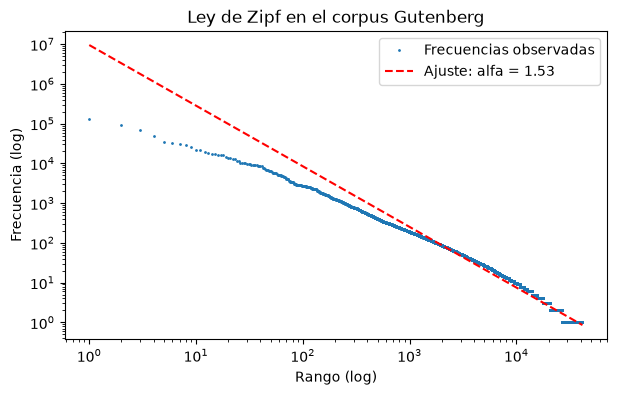

In [5]:
conteos = np.array(sorted(frecuencias.values(), reverse=True))
rangos = np.arange(1, len(conteos) + 1)

# Ajuste lineal en escala log-log para estimar alfa
pendiente, intercepto = np.polyfit(np.log(rangos), np.log(conteos), 1)

plt.figure(figsize=(7, 4))
plt.loglog(rangos, conteos, ".", markersize=2, label="Frecuencias observadas")
plt.loglog(rangos, np.exp(intercepto) * rangos ** pendiente, "r--", label=f"Ajuste: alfa = {-pendiente:.2f}")
plt.xlabel("Rango (log)")
plt.ylabel("Frecuencia (log)")
plt.title("Ley de Zipf en el corpus Gutenberg")
plt.legend()
plt.show()

In [6]:
hapax = sum(1 for c in frecuencias.values() if c == 1)
top_100 = conteos[:100].sum() / conteos.sum()

print(f"Palabras que aparecen una sola vez (hapax legomena): {hapax:,} ({hapax / len(frecuencias):.1%} del vocabulario)")
print(f"Las 100 palabras más frecuentes cubren el {top_100:.1%} de todo el texto")

Palabras que aparecen una sola vez (hapax legomena): 15,002 (36.2% del vocabulario)
Las 100 palabras más frecuentes cubren el 54.7% de todo el texto


**Consecuencias prácticas de la ley de Zipf:**

1. Unas pocas palabras (*the, and, of*...) dominan el texto. Muchas de ellas aportan poca información sobre el tema: por eso a veces se eliminan como *stopwords*.
2. La mayoría del vocabulario es **rara**: siempre aparecerán palabras que el modelo nunca vio en entrenamiento (*out-of-vocabulary*). Esto motiva técnicas como el suavizado (módulo 2) y la tokenización por subpalabras (cuaderno 01).
3. Las representaciones basadas en vocabulario son vectores **enormes y dispersos**, lo que motiva los *embeddings* densos (módulo 3).

<a id="tendencias-actuales"></a>
<h2 style="color: #007ACC;">Tendencias actuales</h2>

Algunas direcciones que marcan el campo hoy:

- **Grandes modelos de lenguaje (LLM):** modelos Transformer con miles de millones de parámetros, preentrenados sobre enormes corpus y adaptados mediante ajuste fino (*fine-tuning*), instrucciones y aprendizaje por refuerzo con retroalimentación humana.
- **Aprendizaje en contexto y *prompting*:** resolver tareas describiéndolas en lenguaje natural, con pocos o ningún ejemplo etiquetado.
- **Generación aumentada con recuperación (RAG):** combinar un LLM con un buscador sobre documentos propios para reducir alucinaciones y usar información actualizada.
- **Agentes:** modelos que usan herramientas (buscadores, código, APIs) para completar tareas de varios pasos.
- **Modelos multimodales:** texto junto con imágenes, audio o video.
- **Eficiencia:** modelos pequeños, cuantización y técnicas de ajuste fino eficiente (LoRA) para ejecutar modelos en hardware modesto.
- **PLN multilingüe y de bajos recursos:** la mayoría de los datos están en inglés; el español y las lenguas indígenas siguen siendo un reto.
- **Ética y evaluación:** sesgos, privacidad, desinformación, alucinaciones y cómo medir de forma confiable la calidad de los modelos (cuaderno 19).

<a id="herramientas-en-python"></a>
<h2 style="color: #007ACC;">Herramientas en Python</h2>

| Librería | Uso principal | Módulos |
|----------|---------------|---------|
| `re` | Expresiones regulares | Todos |
| `nltk` | PLN clásico, corpus y recursos léxicos (WordNet) | 1, 2 |
| `spacy` | Pipelines industriales: tokenización, POS, NER, lematización (incluye español) | 1 |
| `scikit-learn` | Vectorización (BoW, TF-IDF) y modelos clásicos | 1, 2 |
| `gensim` | Word2Vec, GloVe, modelado de tópicos | 3 |
| `tensorflow` / `keras` | Redes neuronales: embeddings, RNN, CNN, Seq2Seq | 3, 4 |
| `transformers` (Hugging Face) | Modelos preentrenados: BERT, GPT, T5 | 4 |
| `datasets` (Hugging Face) | Descarga y manejo de corpus | 4 |

Un vistazo rápido a NLTK: tokenizar una oración y contar palabras.

In [7]:
from nltk.tokenize import word_tokenize

texto = "El procesamiento del lenguaje natural permite que los computadores entiendan el lenguaje. ¡Es fascinante!"
tokens = word_tokenize(texto, language="spanish")
print(tokens)
print(Counter(t.lower() for t in tokens if t.isalpha()).most_common(3))

['El', 'procesamiento', 'del', 'lenguaje', 'natural', 'permite', 'que', 'los', 'computadores', 'entiendan', 'el', 'lenguaje', '.', '¡Es', 'fascinante', '!']
[('el', 2), ('lenguaje', 2), ('procesamiento', 1)]


Observa que el tokenizador dejó `'¡Es'` como un solo token: los tokenizadores entrenados principalmente en inglés no siempre manejan bien la puntuación del español. Detalles como este son los que veremos en el siguiente cuaderno.

<a id="ruta-del-curso"></a>
<h2 style="color: #007ACC;">Ruta del curso</h2>

| Módulo | Semanas | Tema | Idea central |
|--------|---------|------|--------------|
| 1 | 1–2 | Introducción al PLN | Preprocesar texto, convertirlo en vectores y clasificarlo con modelos lineales |
| 2 | 3–4 | Métodos probabilísticos | Modelar secuencias de palabras y etiquetas con probabilidades (N-gramas, HMM, Viterbi, MEMM) |
| 3 | 5–6 | Modelos secuenciales | Aprender representaciones densas (embeddings) y procesar secuencias con RNN, LSTM, GRU y Seq2Seq |
| 4 | 7–8 | Atención y preentrenados | Transformers, BERT, GPT, ajuste fino y aplicaciones; ética de los LLM |

En el siguiente cuaderno empezamos por el primer paso de cualquier sistema de PLN: **preprocesar y tokenizar el texto**.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Bird, S., Klein, E. & Loper, E. (2009). *Natural Language Processing with Python*. O'Reilly Media. [nltk.org/book](https://www.nltk.org/book/)
- Vajjala, S., Majumder, B., Gupta, A. & Surana, H. (2020). *Practical Natural Language Processing*. O'Reilly Media.
- Weizenbaum, J. (1966). ELIZA — A computer program for the study of natural language communication between man and machine. *Communications of the ACM*, 9(1), 36–45.
- Vaswani, A. et al. (2017). Attention Is All You Need. *NeurIPS*.